# 01 — Exploratory Data Analysis (EDA) Dataset IndoTraffic / Poltrada

Notebook ini bersifat **read-only** terhadap dataset.

Tujuan utama:
- memverifikasi struktur dan split dataset,
- memeriksa distribusi kelas dan bounding box,
- mendeteksi label kosong, label hilang, label malformed, dan koordinat tidak valid,
- melihat karakteristik ukuran citra dan bounding box,
- membuat artefak EDA yang dapat dilacak kembali untuk penelitian.

> Notebook ini **tidak** melakukan koreksi anotasi. Koreksi/audit dataset sebaiknya dilakukan pada tahap terpisah agar jejak perubahan data tetap jelas.

## 1. Setup

Notebook mencari root project berdasarkan keberadaan `pyproject.toml`, lalu memuat `.env`.
Tidak ada API key yang dicetak ke output.

In [67]:
# ============================================================
# ENVIRONMENT CONFIGURATION
# Sesuaikan dengan lingkungan yang digunakan:
#   "local"  -> local project (mencari pyproject.toml)
#   "kaggle" -> Kaggle Notebook
#   "colab"  -> Google Colab
# ============================================================

ENV = "local"  # <-- Ganti sesuai kebutuhan: "local" | "kaggle" | "colab"

# Kaggle / Colab: isi nilai berikut secara manual
KAGGLE_ROBOFLOW_WORKSPACE = "ilham-rafiqin"
KAGGLE_ROBOFLOW_PROJECT   = "poltrada-original-raw-2"
KAGGLE_ROBOFLOW_VERSION   = "1"
KAGGLE_DATASET_STAGE      = "validation-audited"
KAGGLE_ROBOFLOW_API_KEY   = ""  # Isi API key Roboflow di sini (jangan commit!)


In [68]:
import os
import json
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from dotenv import load_dotenv

if ENV == "local":
    def find_project_root(start: Path) -> Path:
        current = start.resolve()
        for candidate in [current, *current.parents]:
            if (candidate / "pyproject.toml").exists():
                return candidate
        raise FileNotFoundError("Root project tidak ditemukan.")
    
    ROOT = find_project_root(Path.cwd())
    load_dotenv(ROOT / ".env")
    print("Mode: LOCAL | Project root:", ROOT)

elif ENV == "kaggle":
    ROOT = Path("/kaggle/working")
    os.environ["ROBOFLOW_WORKSPACE"] = KAGGLE_ROBOFLOW_WORKSPACE
    os.environ["ROBOFLOW_PROJECT"]   = KAGGLE_ROBOFLOW_PROJECT
    os.environ["ROBOFLOW_VERSION"]   = KAGGLE_ROBOFLOW_VERSION
    os.environ["DATASET_STAGE"]      = KAGGLE_DATASET_STAGE
    os.environ["ROBOFLOW_API_KEY"]   = KAGGLE_ROBOFLOW_API_KEY
    print("Mode: KAGGLE | Working dir:", ROOT)

elif ENV == "colab":
    # Optional: mount drive for colab
    # from google.colab import drive
    # drive.mount('/content/drive')
    ROOT = Path("/content")
    os.environ["ROBOFLOW_WORKSPACE"] = KAGGLE_ROBOFLOW_WORKSPACE
    os.environ["ROBOFLOW_PROJECT"]   = KAGGLE_ROBOFLOW_PROJECT
    os.environ["ROBOFLOW_VERSION"]   = KAGGLE_ROBOFLOW_VERSION
    os.environ["DATASET_STAGE"]      = KAGGLE_DATASET_STAGE
    os.environ["ROBOFLOW_API_KEY"]   = KAGGLE_ROBOFLOW_API_KEY
    print("Mode: COLAB | Working dir:", ROOT)

else:
    raise ValueError(f"ENV tidak dikenal: {ENV!r}")


Mode: LOCAL | Project root: C:\Local D\Galeri Belajar\Skripsi


## 2. Konfigurasi eksperimen data

Nilai Roboflow diambil dari `.env`. Folder output EDA dipisahkan dari dataset sumber.

In [69]:
ROBOFLOW_WORKSPACE = os.getenv("ROBOFLOW_WORKSPACE")
ROBOFLOW_PROJECT = os.getenv("ROBOFLOW_PROJECT")
ROBOFLOW_VERSION = os.getenv("ROBOFLOW_VERSION")
DATASET_STAGE = os.getenv("DATASET_STAGE", "unspecified")

required = {
    "ROBOFLOW_WORKSPACE": ROBOFLOW_WORKSPACE,
    "ROBOFLOW_PROJECT": ROBOFLOW_PROJECT,
    "ROBOFLOW_VERSION": ROBOFLOW_VERSION,
}

missing = [key for key, value in required.items() if not value]
if missing:
    raise RuntimeError(f"Variabel .env belum lengkap: {', '.join(missing)}")

DATASET_ID = f"{ROBOFLOW_PROJECT}-v{ROBOFLOW_VERSION}"
DATASET_DIR = ROOT / "data" / "raw" / DATASET_ID
EDA_DIR = ROOT / "outputs" / "eda" / DATASET_ID
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset ID   :", DATASET_ID)
print("Dataset stage:", DATASET_STAGE)
print("Dataset dir  :", DATASET_DIR)
print("EDA output   :", EDA_DIR)

Dataset ID   : poltrada-original-raw-2-v1
Dataset stage: validation-audited
Dataset dir  : C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1
EDA output   : C:\Local D\Galeri Belajar\Skripsi\outputs\eda\poltrada-original-raw-2-v1


## 3. Download dataset dari Roboflow (jalankan hanya bila dataset belum ada)

Cell ini hanya mengunduh versi yang ditunjuk oleh `.env`.
Jika dataset sudah ada di `DATASET_DIR`, download dilewati.

In [70]:
## 4. Baca `data.yaml` dan resolve path split

Kita mengikuti path yang tercatat pada `data.yaml` secara robust, bukan mengasumsikan nama folder secara manual.

SyntaxError: invalid syntax (1153300138.py, line 3)

### Verifikasi Struktur Folder Dataset
Melihat isi dari direktori dataset yang telah diunduh.

In [ ]:
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

names = data_cfg.get("names", [])
if isinstance(names, dict):
    class_names = [names[k] for k in sorted(names, key=lambda x: int(x))]
else:
    class_names = list(names)

nc = data_cfg.get("nc", len(class_names))

def resolve_yaml_path(value):
    if value is None:
        return None
    path = Path(value)
    if not path.is_absolute():
        path = (DATA_YAML.parent / path).resolve()
    return path

split_dirs = {
    "train": resolve_yaml_path(data_cfg.get("train")),
    "val": resolve_yaml_path(data_cfg.get("val") or data_cfg.get("valid")),
    "test": resolve_yaml_path(data_cfg.get("test")),
}

print("Classes:", class_names)
print("nc     :", nc)
for split, path in split_dirs.items():
    print(f"{split:5} :", path)

Classes: ['Bus', 'Mobil Penumpang', 'Pejalan Kaki', 'Sepeda Motor', 'Truck', 'Unmotorized']
nc     : 6
train : C:\Local D\Galeri Belajar\Skripsi\data\raw\train\images
val   : C:\Local D\Galeri Belajar\Skripsi\data\raw\valid\images
test  : C:\Local D\Galeri Belajar\Skripsi\data\raw\test\images


In [ ]:
for item in DATASET_DIR.iterdir():
    print(
        "[DIR] " if item.is_dir() else "[FILE]",
        item.name,
    )

[FILE] data.yaml
[FILE] README.dataset.txt
[FILE] README.roboflow.txt
[DIR]  test
[DIR]  train
[DIR]  valid


## 5. Inventarisasi citra dan label

Untuk setiap split kita menghitung jumlah citra, mencari folder label pasangannya, dan membangun indeks data.

In [ ]:
# ============================================================
# RESOLVE DATASET SPLITS ROBUSTLY
# ============================================================

from pathlib import Path
import pandas as pd
import yaml


# ------------------------------------------------------------
# 1. Baca data.yaml
# ------------------------------------------------------------

print("DATASET_DIR :", DATASET_DIR)
print("DATA_YAML   :", DATA_YAML)

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"data.yaml tidak ditemukan:\n{DATA_YAML}"
    )


with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)


print("\nIsi data.yaml:")
print(data_cfg)


# ------------------------------------------------------------
# 2. Class names
# ------------------------------------------------------------

names = data_cfg.get("names", [])

if isinstance(names, dict):
    class_names = [
        names[k]
        for k in sorted(names, key=lambda x: int(x))
    ]
else:
    class_names = list(names)


print("\nClasses:")
for idx, name in enumerate(class_names):
    print(f"  {idx}: {name}")


# ------------------------------------------------------------
# 3. Resolve path split
# ------------------------------------------------------------

SPLIT_ALIASES = {
    "train": ["train"],
    "val": ["valid", "val"],
    "test": ["test"],
}


def resolve_split_dir(
    split_name: str,
    yaml_value,
) -> Path:

    candidates = []

    # --------------------------------------------------------
    # Kandidat berdasarkan data.yaml
    # --------------------------------------------------------

    if yaml_value:

        yaml_path = Path(
            str(yaml_value)
        )

        if yaml_path.is_absolute():
            candidates.append(
                yaml_path
            )

        else:

            # Kandidat 1:
            # relatif terhadap lokasi data.yaml
            candidates.append(
                (
                    DATA_YAML.parent
                    / yaml_path
                ).resolve()
            )

            # Kandidat 2:
            # hilangkan ../ jika Roboflow memakai path seperti
            # ../train/images
            clean_parts = [
                part
                for part in yaml_path.parts
                if part not in ("..", ".")
            ]

            if clean_parts:

                candidates.append(
                    (
                        DATASET_DIR
                        / Path(*clean_parts)
                    ).resolve()
                )


    # --------------------------------------------------------
    # Kandidat berdasarkan struktur standar Roboflow
    # --------------------------------------------------------

    for folder_name in SPLIT_ALIASES[
        split_name
    ]:

        candidates.append(
            (
                DATASET_DIR
                / folder_name
                / "images"
            ).resolve()
        )


    # --------------------------------------------------------
    # Cari kandidat pertama yang benar-benar tersedia
    # --------------------------------------------------------

    checked = []

    for candidate in candidates:

        if candidate in checked:
            continue

        checked.append(
            candidate
        )

        if candidate.exists() and candidate.is_dir():

            return candidate


    # Tidak ditemukan
    print(
        f"\n[ERROR] Split '{split_name}' "
        "tidak ditemukan."
    )

    print(
        "Path yang sudah diperiksa:"
    )

    for candidate in checked:
        print(
            " -",
            candidate,
            "| exists:",
            candidate.exists(),
        )


    raise FileNotFoundError(
        f"Folder images untuk split "
        f"'{split_name}' tidak ditemukan."
    )


# ------------------------------------------------------------
# 4. Resolve ketiga split
# ------------------------------------------------------------

split_dirs = {
    "train": resolve_split_dir(
        "train",
        data_cfg.get("train"),
    ),

    "val": resolve_split_dir(
        "val",
        data_cfg.get("val")
        or data_cfg.get("valid"),
    ),

    "test": resolve_split_dir(
        "test",
        data_cfg.get("test"),
    ),
}


print("\nResolved dataset splits:")
print("=" * 70)

for split, path in split_dirs.items():

    print(
        f"{split:5} -> {path}"
    )

DATASET_DIR : C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1
DATA_YAML   : C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1\data.yaml

Isi data.yaml:
{'names': ['Bus', 'Mobil Penumpang', 'Pejalan Kaki', 'Sepeda Motor', 'Truck', 'Unmotorized'], 'nc': 6, 'roboflow': {'license': 'CC BY 4.0', 'project': 'poltrada-original-raw-2', 'url': 'https://universe.roboflow.com/ilham-rafiqin/poltrada-original-raw-2/dataset/1', 'version': 1, 'workspace': 'ilham-rafiqin'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}

Classes:
  0: Bus
  1: Mobil Penumpang
  2: Pejalan Kaki
  3: Sepeda Motor
  4: Truck
  5: Unmotorized

Resolved dataset splits:
train -> C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1\train\images
val   -> C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1\valid\images
test  -> C:\Local D\Galeri Belajar\Skripsi\data\raw\poltrada-original-raw-2-v1\test\images


### 5b. Ringkasan Label: Kosong vs. Hilang
Menghitung jumlah citra, label yang ada, label kosong, dan label yang hilang dari setiap split dataset.

In [ ]:
# ============================================================
# REBUILD IMAGE INVENTORY
# ============================================================

from pathlib import Path
import pandas as pd


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
    ".tif",
    ".tiff",
}


def list_images(images_dir: Path):
    return sorted(
        path
        for path in images_dir.rglob("*")
        if (
            path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        )
    )


records = []


for split, images_dir in split_dirs.items():

    labels_dir = (
        images_dir.parent
        / "labels"
    )

    images = list_images(
        images_dir
    )

    print(
        f"{split:5} | "
        f"images={len(images)} | "
        f"labels_dir={labels_dir.exists()}"
    )

    for image_path in images:

        relative_path = (
            image_path.relative_to(
                images_dir
            )
        )

        label_path = (
            labels_dir
            / relative_path.with_suffix(
                ".txt"
            )
        )

        records.append(
            {
                "split": split,
                "image_path": str(image_path),
                "label_path": str(label_path),
                "image_name": image_path.name,
                "label_exists": label_path.exists(),
            }
        )


images_df = pd.DataFrame(
    records,
    columns=[
        "split",
        "image_path",
        "label_path",
        "image_name",
        "label_exists",
    ],
)


if images_df.empty:
    raise RuntimeError(
        "images_df kosong. "
        "Tidak ada gambar yang ditemukan."
    )


print()
print("Shape:", images_df.shape)
print("Columns:", images_df.columns.tolist())

display(
    images_df.head()
)

train | images=6775 | labels_dir=True
val   | images=1790 | labels_dir=True
test  | images=913 | labels_dir=True

Shape: (9478, 5)
Columns: ['split', 'image_path', 'label_path', 'image_name', 'label_exists']


,split,image_path,label_path,image_name,label_exists
0,train,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,True
1,train,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00001_...,True
2,train,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00002_...,True
3,train,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00005_...,True
4,train,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00006_...,True


In [ ]:
# ============================================================
# EMPTY / MISSING LABEL ANALYSIS
# ============================================================

def is_empty_label(path_str):

    path = Path(path_str)

    if not path.exists():
        return False

    return (
        path.read_text(
            encoding="utf-8"
        ).strip()
        == ""
    )


images_df["label_empty"] = (
    images_df["label_path"]
    .apply(is_empty_label)
)


label_quality_summary = (
    images_df
    .groupby(
        "split",
        as_index=False,
    )
    .agg(
        images=(
            "image_path",
            "count",
        ),
        labels_present=(
            "label_exists",
            "sum",
        ),
        empty_labels=(
            "label_empty",
            "sum",
        ),
    )
)


label_quality_summary[
    "missing_labels"
] = (
    label_quality_summary["images"]
    - label_quality_summary["labels_present"]
)


display(
    label_quality_summary
)

,split,images,labels_present,empty_labels,missing_labels
0,test,913,913,9,0
1,train,6775,6775,16,0
2,val,1790,1790,2,0


## 6. Parse anotasi YOLO

Format yang diharapkan per baris:

`class_id x_center y_center width height`

Parser juga mencatat baris malformed, class ID tidak valid, dan koordinat di luar rentang normalisasi.

In [ ]:
annotation_rows = []
issue_rows = []

for row in images_df.itertuples(index=False):
    image_path = Path(row.image_path)
    label_path = Path(row.label_path)

    if not label_path.exists():
        issue_rows.append({
            "split": row.split,
            "image_name": row.image_name,
            "issue": "missing_label_file",
            "detail": str(label_path),
        })
        continue

    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        issue_rows.append({
            "split": row.split,
            "image_name": row.image_name,
            "issue": "empty_label_file",
            "detail": str(label_path),
        })
        continue

    for line_number, line in enumerate(text.splitlines(), start=1):
        parts = line.split()

        if len(parts) != 5:
            issue_rows.append({
                "split": row.split,
                "image_name": row.image_name,
                "issue": "malformed_label",
                "detail": f"line={line_number}, values={len(parts)}",
            })
            continue

        try:
            class_id = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            issue_rows.append({
                "split": row.split,
                "image_name": row.image_name,
                "issue": "non_numeric_label",
                "detail": f"line={line_number}",
            })
            continue

        if class_id < 0 or class_id >= len(class_names):
            issue_rows.append({
                "split": row.split,
                "image_name": row.image_name,
                "issue": "invalid_class_id",
                "detail": f"line={line_number}, class_id={class_id}",
            })

        if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            issue_rows.append({
                "split": row.split,
                "image_name": row.image_name,
                "issue": "invalid_normalized_coordinates",
                "detail": f"line={line_number}, x={x}, y={y}, w={w}, h={h}",
            })

        x1 = x - w / 2
        y1 = y - h / 2
        x2 = x + w / 2
        y2 = y + h / 2

        if x1 < 0 or y1 < 0 or x2 > 1 or y2 > 1:
            issue_rows.append({
                "split": row.split,
                "image_name": row.image_name,
                "issue": "box_extends_outside_image",
                "detail": f"line={line_number}",
            })

        annotation_rows.append({
            "split": row.split,
            "image_name": row.image_name,
            "label_path": str(label_path),
            "line_number": line_number,
            "class_id": class_id,
            "class_name": class_names[class_id] if 0 <= class_id < len(class_names) else "INVALID",
            "x_center": x,
            "y_center": y,
            "width_norm": w,
            "height_norm": h,
            "area_norm": w * h,
            "aspect_ratio_bbox": w / h if h > 0 else np.nan,
        })

annotations_df = pd.DataFrame(annotation_rows)
issues_df = pd.DataFrame(issue_rows)

print("Total annotations parsed:", len(annotations_df))
print("Total issues found       :", len(issues_df))

Total annotations parsed: 172566
Total issues found       : 87


### 7b. Visualisasi Distribusi Kelas
Membuat bar chart untuk melihat proporsi anotasi setiap kelas.

## 7. Distribusi anotasi per split dan kelas

## 8. Statistik Ukuran Citra
Menganalisis resolusi (width, height) dan rasio aspek dari seluruh citra dalam dataset.

In [ ]:
class_distribution = (
    annotations_df
    .groupby(["split", "class_id", "class_name"])
    .size()
    .rename("annotations")
    .reset_index()
)

class_pivot = (
    class_distribution
    .pivot_table(
        index=["class_id", "class_name"],
        columns="split",
        values="annotations",
        fill_value=0,
    )
    .reset_index()
)

for split in ["train", "val", "test"]:
    if split not in class_pivot.columns:
        class_pivot[split] = 0

class_pivot["total"] = class_pivot[["train", "val", "test"]].sum(axis=1)
class_pivot["proportion_pct"] = 100 * class_pivot["total"] / class_pivot["total"].sum()

class_pivot

split,class_id,class_name,test,train,val,total,proportion_pct
0,0,Bus,41.0,383.0,97.0,521.0,0.301913
1,1,Mobil Penumpang,5272.0,40984.0,11024.0,57280.0,33.193097
2,2,Pejalan Kaki,464.0,3430.0,946.0,4840.0,2.804724
3,3,Sepeda Motor,9024.0,74836.0,18750.0,102610.0,59.461308
4,4,Truck,562.0,5224.0,1184.0,6970.0,4.039034
5,5,Unmotorized,38.0,237.0,70.0,345.0,0.199924


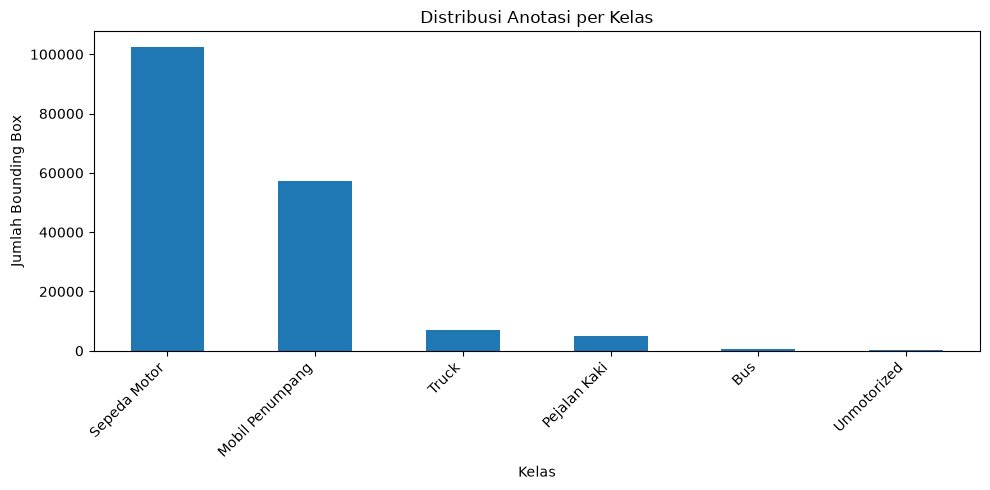

In [ ]:
plot_df = (
    annotations_df.groupby("class_name")
    .size()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df.plot(kind="bar", ax=ax)
ax.set_title("Distribusi Anotasi per Kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah Bounding Box")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 8. Jumlah objek per citra

Bagian ini berguna untuk memahami kepadatan anotasi dan mencari citra dengan jumlah objek sangat tinggi atau nol.

### 10b. Visualisasi Luas Bounding Box
Melihat distribusi luas bounding box ternormalisasi untuk mendeteksi sebaran ukuran objek.

In [ ]:
objects_per_image = (
    annotations_df.groupby(["split", "image_name"])
    .size()
    .rename("objects")
    .reset_index()
)

# Tambahkan citra yang tidak memiliki anotasi terparse.
objects_per_image = (
    images_df[["split", "image_name"]]
    .merge(objects_per_image, on=["split", "image_name"], how="left")
)
objects_per_image["objects"] = objects_per_image["objects"].fillna(0).astype(int)

objects_per_image.groupby("split")["objects"].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,913.0,16.868565,15.607446,0.0,4.0,13.0,25.0,74.0
train,6775.0,18.464059,16.341928,0.0,4.0,15.0,29.0,81.0
val,1790.0,17.916760,15.281641,0.0,6.0,13.0,26.0,80.0


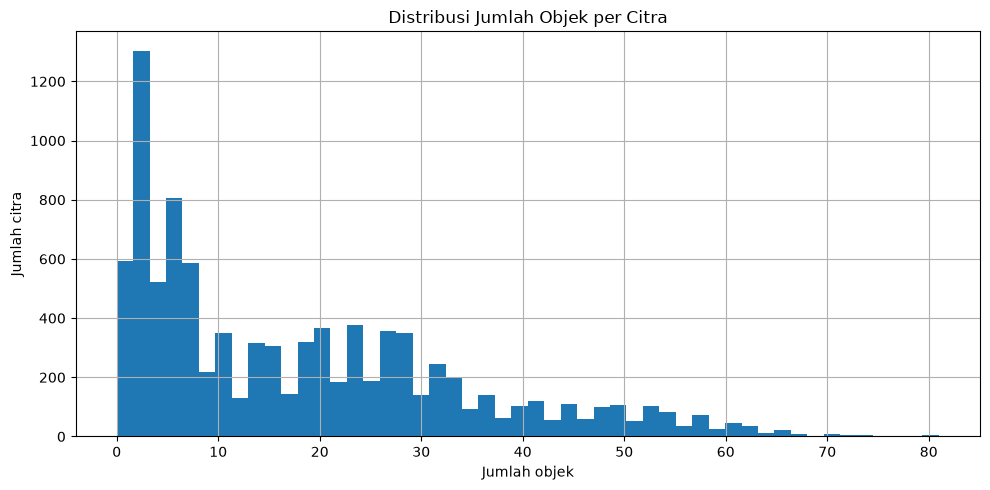

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
objects_per_image["objects"].hist(bins=50, ax=ax)
ax.set_title("Distribusi Jumlah Objek per Citra")
ax.set_xlabel("Jumlah objek")
ax.set_ylabel("Jumlah citra")
plt.tight_layout()
plt.show()

## 9. Dimensi citra

Pembacaan hanya metadata ukuran citra; file tidak dimodifikasi.

## 12. Master DataFrame EDA (ann_eda)
Menggabungkan data anotasi dan data dimensi citra untuk analisis lebih lanjut (kepadatan, IoA, skala COCO, dll).

In [ ]:
dimension_rows = []

for row in images_df.itertuples(index=False):
    image_path = Path(row.image_path)
    try:
        with Image.open(image_path) as img:
            width, height = img.size
        dimension_rows.append({
            "split": row.split,
            "image_name": row.image_name,
            "image_width": width,
            "image_height": height,
            "image_aspect_ratio": width / height,
        })
    except Exception as exc:
        issue_rows.append({
            "split": row.split,
            "image_name": row.image_name,
            "issue": "image_read_error",
            "detail": repr(exc),
        })

dimensions_df = pd.DataFrame(dimension_rows)
issues_df = pd.DataFrame(issue_rows)

dimensions_df.groupby("split")[["image_width", "image_height", "image_aspect_ratio"]].describe()

image_width                                                           \
            count         mean         std     min     25%     50%     75%   
split                                                                        
test        913.0  1553.141292  491.730482  1280.0  1280.0  1280.0  1920.0   
train      6775.0  1541.241033  484.402969  1280.0  1280.0  1280.0  1920.0   
val        1790.0  1563.181006  498.706120  1280.0  1280.0  1280.0  1920.0   

              image_height              ...                  \
          max        count        mean  ...     75%     max   
split                                   ...                   
test   3024.0        913.0  874.435926  ...  1080.0  1712.0   
train  3024.0       6775.0  867.700959  ...  1080.0  1712.0   
val    3024.0       1790.0  880.105028  ...  1080.0  1712.0   

      image_aspect_ratio                                                    \
                   count      mean       std       min       25%       50%   
split                                                                        
test               913.0  1.776959  0.003619  1.760514  1.777778  1.777778   
train             6775.0  1.777001  0.003532  1.760514  1.777778  1.777778   
val               1790.0  1.776937  0.003676  1.760514  1.777778  1.777778   

                           
            75%       max  
split                      
test   1.777778  1.784314  
train  1.777778  1.784314  
val    1.777778  1.784314  

[3 rows x 24 columns]

## 13. Analisis Skala Objek (COCO)
Mengkategorikan ukuran objek menjadi Small, Medium, dan Large berdasarkan konvensi COCO (area dalam piksel persegi).

In [ ]:
annotations_df[["width_norm", "height_norm", "area_norm", "aspect_ratio_bbox"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

,width_norm,height_norm,area_norm,aspect_ratio_bbox
count,172566.000000,172566.000000,172566.000000,172566.000000
mean,0.040253,0.071325,0.004982,0.535668
std,0.045547,0.056729,0.014980,0.265853
min,0.002654,0.005862,0.000020,0.057528
1%,0.006250,0.015826,0.000118,0.189731
5%,0.008594,0.022222,0.000215,0.246094
25%,0.015625,0.038889,0.000639,0.337500
50%,0.025781,0.055556,0.001423,0.488487
75%,0.046875,0.084259,0.003772,0.658537
95%,0.121354,0.172788,0.019016,1.022222


### 13a. Visualisasi Skala Objek COCO
Proporsi bounding box dalam setiap kategori skala.

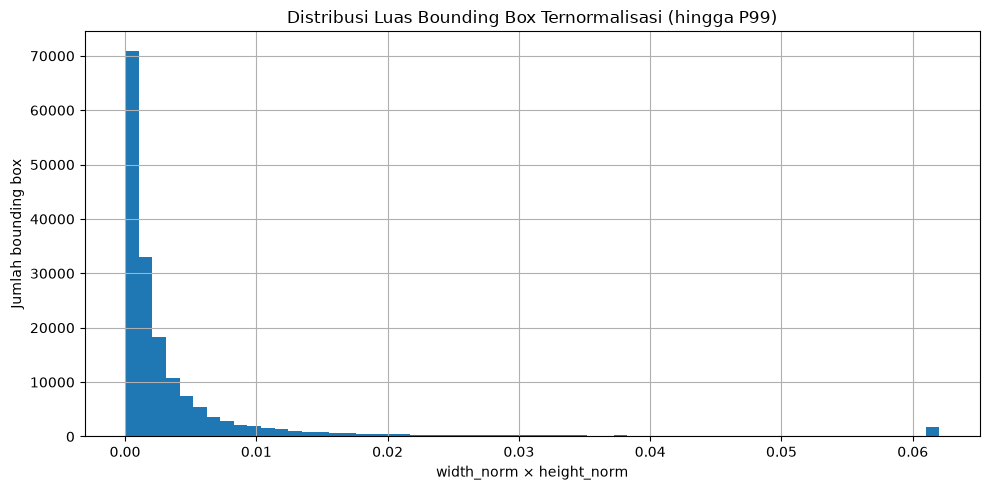

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
annotations_df["area_norm"].clip(upper=annotations_df["area_norm"].quantile(0.99)).hist(
    bins=60,
    ax=ax,
)
ax.set_title("Distribusi Luas Bounding Box Ternormalisasi (hingga P99)")
ax.set_xlabel("width_norm × height_norm")
ax.set_ylabel("Jumlah bounding box")
plt.tight_layout()
plt.show()

### 13b. Distribusi Skala per Kelas
Melihat kategori skala apa yang mendominasi di setiap kelas (misal: apakah pejalan kaki didominasi skala Small?).

In [ ]:
if len(issues_df):
    issue_summary = (
        issues_df.groupby(["split", "issue"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(["split", "count"], ascending=[True, False])
    )
else:
    issue_summary = pd.DataFrame(columns=["split", "issue", "count"])

issue_summary

,split,issue,count
1,test,empty_label_file,9
0,test,box_extends_outside_image,4
2,test,malformed_label,2
3,train,box_extends_outside_image,24
4,train,empty_label_file,16
5,train,malformed_label,14
6,val,box_extends_outside_image,12
8,val,malformed_label,4
7,val,empty_label_file,2


### 13c. Distribusi Skala per Split
Memverifikasi apakah sebaran skala objek seimbang antara set train, val, dan test.

In [ ]:
name_split_counts = (
    images_df.groupby("image_name")["split"]
    .nunique()
    .sort_values(ascending=False)
)

duplicate_names_across_splits = name_split_counts[name_split_counts > 1]

print("Nama file yang muncul di >1 split:", len(duplicate_names_across_splits))
duplicate_names_across_splits.head(20)

Nama file yang muncul di >1 split: 0


Series([], Name: split, dtype: int64)

## 14. Kepadatan Objek per Gambar
Menganalisis seberapa banyak objek yang ada di dalam satu gambar (object count per image).

## 13. Visual sanity check

Menampilkan beberapa sampel acak beserta ground-truth bounding box.

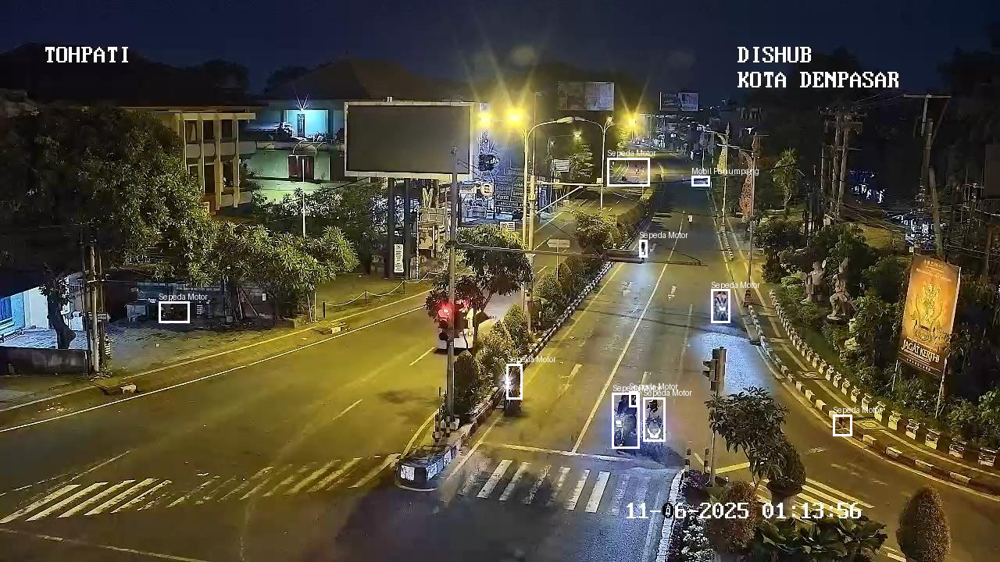

train - TOHPATI-11_06_2025-00_32_30_frame_00083_jpg.rf.8b02a9758cdb31f0f964862813ae7868.jpg


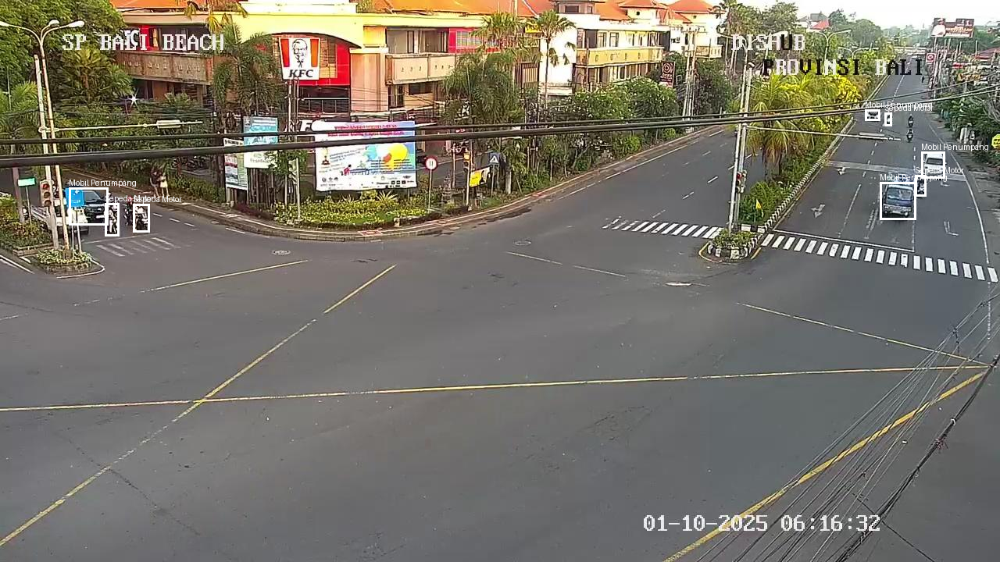

train - SP_BALI_BEACH-01_10_2025-06_02_45_frame_00827_jpg.rf.d7b4c9cab3f8bf00d512d268a9268d1e.jpg


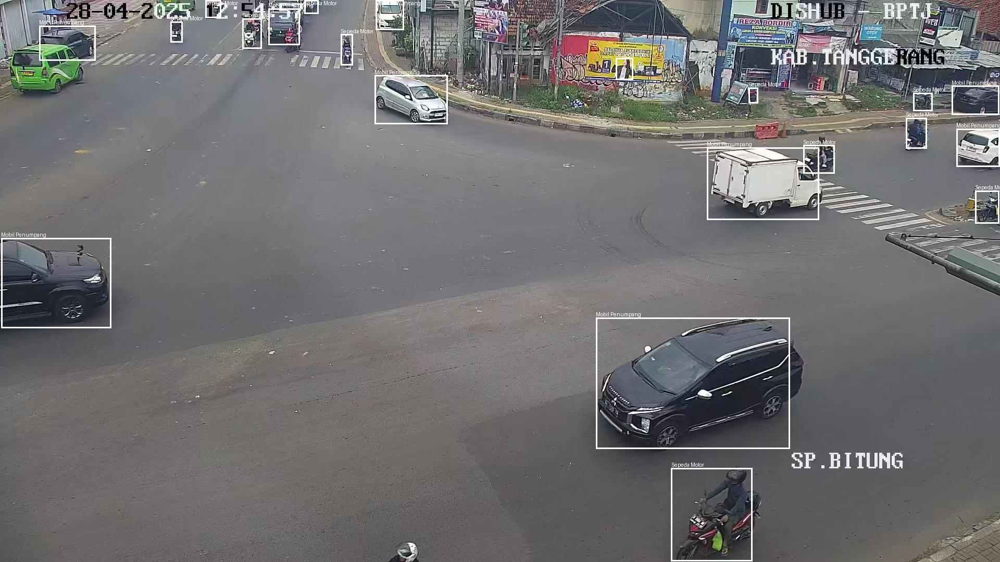

val - SP_BITUNG-28_04_2025-11_40_57_frame_00148_jpg.rf.482b9bf8c88a7de05c2a6262cdfb86a7.jpg


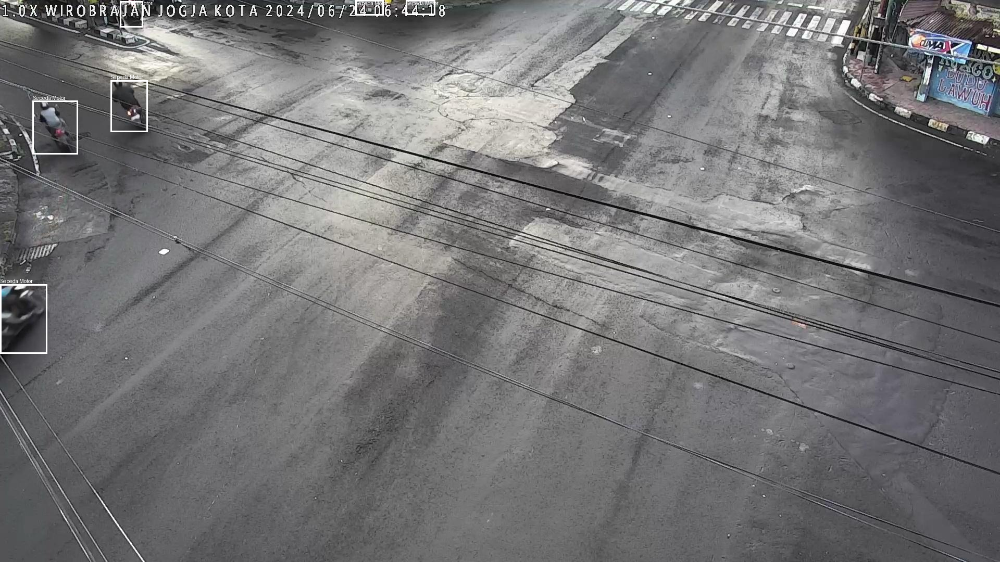

test - Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00547_jpg.rf.2ccf92b80f7d70b2e867c601064a1e52.jpg


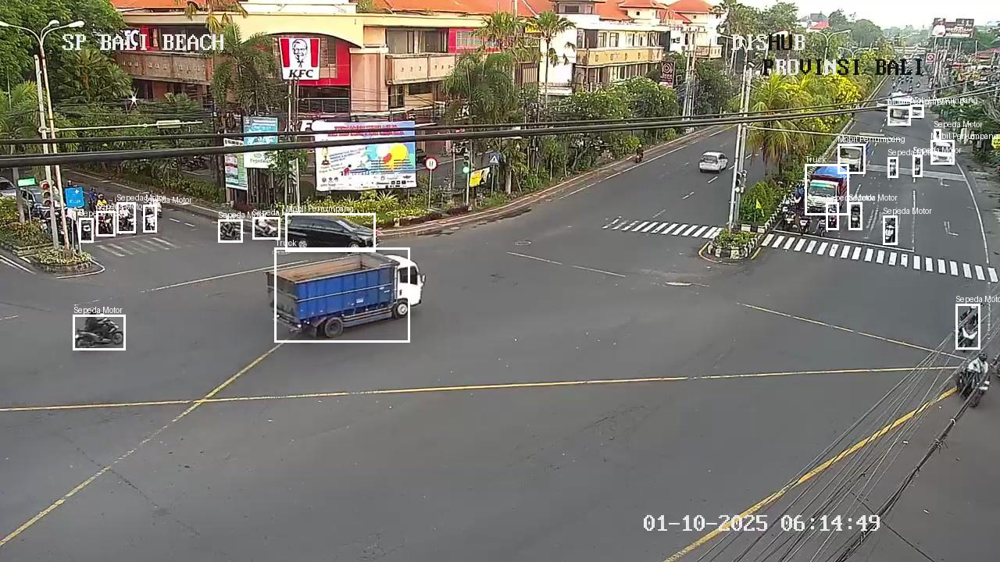

train - SP_BALI_BEACH-01_10_2025-06_02_45_frame_00724_jpg.rf.4a7ad2c10245e6cb06c7ec9e9568c4a9.jpg


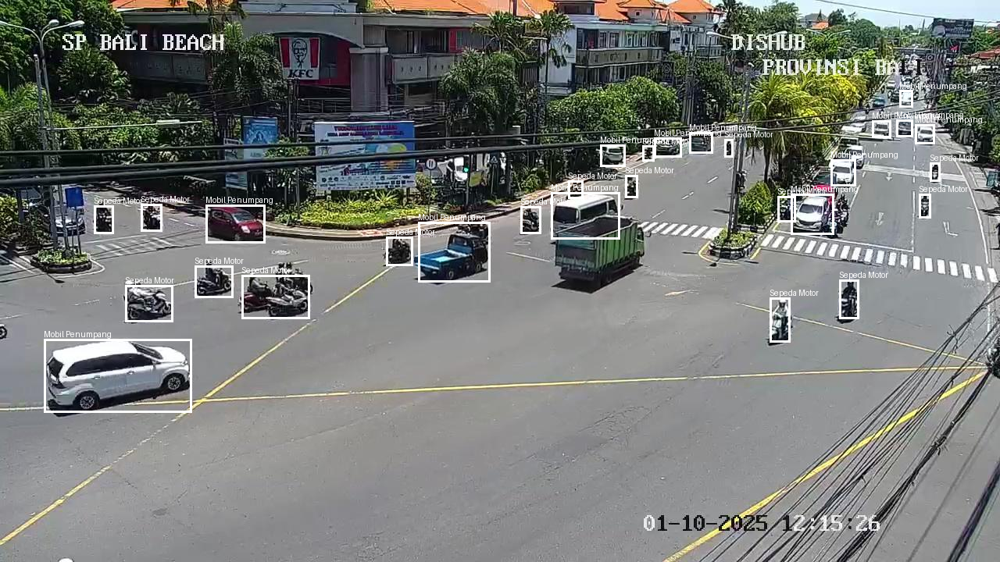

train - SP_BALI_BEACH-01-10-2025-12-11-03_frame_00263_jpg.rf.9d24c387379b7665368ba6d85b5d4ebd.jpg


In [ ]:
def draw_yolo_boxes(image_path: Path, label_path: Path, class_names):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    if label_path.exists():
        text = label_path.read_text(encoding="utf-8").strip()
        for line in text.splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])

            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height
            x2 = (x + w / 2) * width
            y2 = (y + h / 2) * height

            draw.rectangle([x1, y1, x2, y2], width=3)

            label = (
                class_names[class_id]
                if 0 <= class_id < len(class_names)
                else f"class_{class_id}"
            )
            draw.text((x1, max(0, y1 - 12)), label)

    return image


sample_n = min(6, len(images_df))
sample_rows = images_df.sample(sample_n, random_state=42)

for row in sample_rows.itertuples(index=False):
    display(draw_yolo_boxes(
        Path(row.image_path),
        Path(row.label_path),
        class_names,
    ))
    print(row.split, "-", row.image_name)

### 14b. Visualisasi Kepadatan Objek
Distribusi jumlah objek per gambar dalam dataset.

In [ ]:
# ============================================================
# MASTER EDA DATAFRAME
# ============================================================

ann_eda = annotations_df.merge(
    dimensions_df[
        [
            "split",
            "image_name",
            "image_width",
            "image_height",
            "image_aspect_ratio",
        ]
    ],
    on=["split", "image_name"],
    how="left",
)

ann_eda["bbox_width_px"] = (
    ann_eda["width_norm"]
    * ann_eda["image_width"]
)

ann_eda["bbox_height_px"] = (
    ann_eda["height_norm"]
    * ann_eda["image_height"]
)

ann_eda["bbox_area_px"] = (
    ann_eda["bbox_width_px"]
    * ann_eda["bbox_height_px"]
)

ann_eda["bbox_aspect_ratio"] = (
    ann_eda["bbox_width_px"]
    / ann_eda["bbox_height_px"]
)

print("Annotations :", len(ann_eda))
print("Images      :", len(images_df))

display(
    ann_eda.head()
)

Annotations : 172566
Images      : 9478


,split,image_name,label_path,line_number,class_id,class_name,x_center,y_center,width_norm,height_norm,area_norm,aspect_ratio_bbox,image_width,image_height,image_aspect_ratio,bbox_width_px,bbox_height_px,bbox_area_px,bbox_aspect_ratio
0,train,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,1,3,Sepeda Motor,0.937760,0.261574,0.056771,0.087963,0.004994,0.645395,1920,1080,1.777778,109.0,95.0,10355.0,1.147368
1,train,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,2,1,Mobil Penumpang,0.091927,0.418056,0.138021,0.189815,0.026198,0.727134,1920,1080,1.777778,265.0,205.0,54325.0,1.292683
2,train,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,3,3,Sepeda Motor,0.697396,0.496296,0.036458,0.162963,0.005941,0.223722,1920,1080,1.777778,70.0,176.0,12320.0,0.397727
3,train,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,4,1,Mobil Penumpang,0.578646,0.321759,0.103125,0.193519,0.019957,0.532895,1920,1080,1.777778,198.0,209.0,41382.0,0.947368
4,train,Ctmc-Simpang-Wirobrajan-6_00-8_00_frame_00000_...,C:\Local D\Galeri Belajar\Skripsi\data\raw\pol...,5,3,Sepeda Motor,0.598437,0.716204,0.045833,0.180556,0.008275,0.253846,1920,1080,1.777778,88.0,195.0,17160.0,0.451282


## 15. Tumpang-Tindih Bounding Box (IoA)
Menghitung Intersection over Area (IoA) untuk mengukur tingkat tumpang-tindih (oklusi) antar objek dalam satu gambar.

## Analisis skala objek COCO

In [ ]:
# ============================================================
# COCO SCALE CLASSIFICATION
# ============================================================

SMALL_THRESHOLD = 32 ** 2
MEDIUM_THRESHOLD = 96 ** 2


def classify_coco_scale(area):
    if area < SMALL_THRESHOLD:
        return "Small"

    if area < MEDIUM_THRESHOLD:
        return "Medium"

    return "Large"


ann_eda["coco_scale"] = (
    ann_eda["bbox_area_px"]
    .apply(classify_coco_scale)
)


scale_summary = (
    ann_eda["coco_scale"]
    .value_counts()
    .reindex(
        ["Small", "Medium", "Large"],
        fill_value=0,
    )
    .rename_axis("scale")
    .reset_index(name="count")
)

scale_summary["percentage"] = (
    scale_summary["count"]
    / scale_summary["count"].sum()
    * 100
)

display(scale_summary)

,scale,count,percentage
0,Small,56939,32.995492
1,Medium,88575,51.328187
2,Large,27052,15.676321


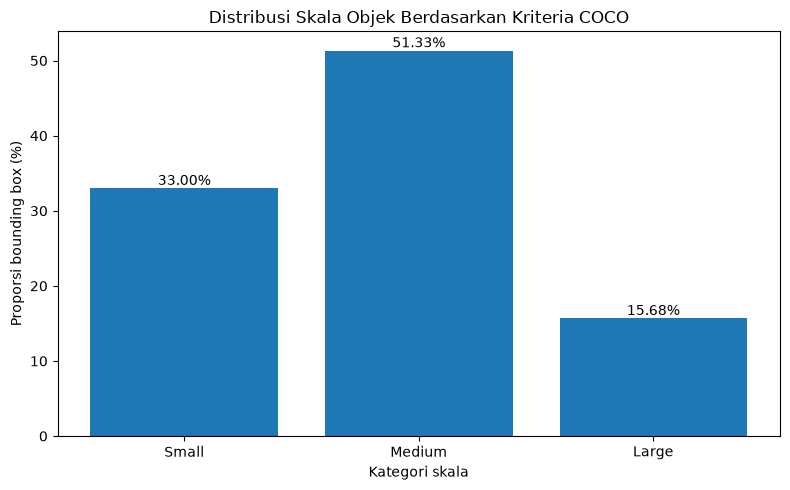

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    scale_summary["scale"],
    scale_summary["percentage"],
)

ax.set_title(
    "Distribusi Skala Objek Berdasarkan Kriteria COCO"
)

ax.set_xlabel(
    "Kategori skala"
)

ax.set_ylabel(
    "Proporsi bounding box (%)"
)

for bar, value in zip(
    bars,
    scale_summary["percentage"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Distribusi skala per kelas

In [ ]:
# ============================================================
# COCO SCALE × CLASS
# ============================================================

class_scale = (
    ann_eda
    .groupby(
        [
            "class_name",
            "coco_scale",
        ],
        observed=False,
    )
    .size()
    .rename("count")
    .reset_index()
)


class_scale_pivot = (
    class_scale
    .pivot(
        index="class_name",
        columns="coco_scale",
        values="count",
    )
    .fillna(0)
    .reindex(
        columns=[
            "Small",
            "Medium",
            "Large",
        ],
        fill_value=0,
    )
)


display(class_scale_pivot)

coco_scale,Small,Medium,Large
class_name,,,
Bus,4.0,124.0,393.0
Mobil Penumpang,11903.0,31413.0,13964.0
Pejalan Kaki,1408.0,3108.0,324.0
Sepeda Motor,43479.0,51906.0,7225.0
Truck,145.0,1848.0,4977.0
Unmotorized,0.0,176.0,169.0


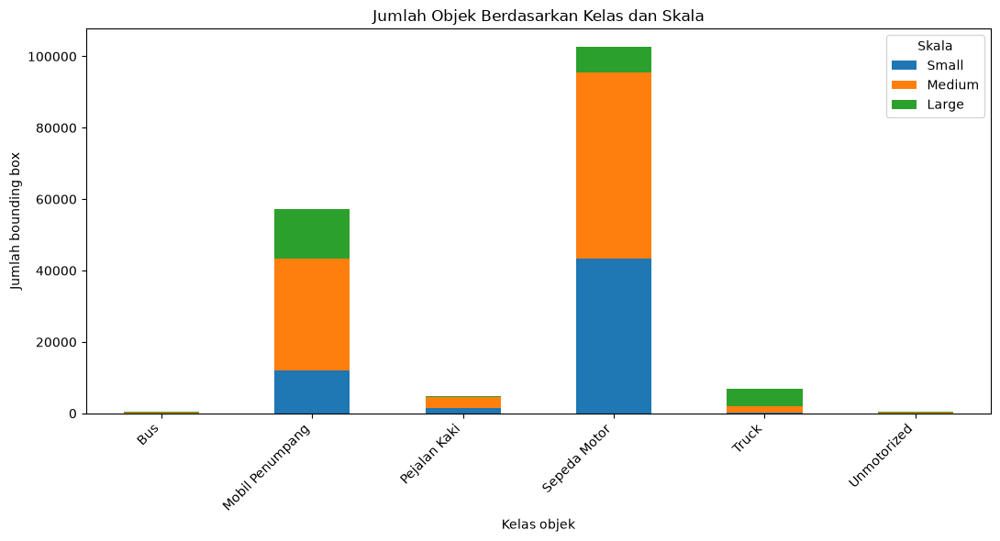

In [ ]:
ax = class_scale_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
)

ax.set_title(
    "Jumlah Objek Berdasarkan Kelas dan Skala"
)

ax.set_xlabel(
    "Kelas objek"
)

ax.set_ylabel(
    "Jumlah bounding box"
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.legend(
    title="Skala"
)

plt.tight_layout()
plt.show()

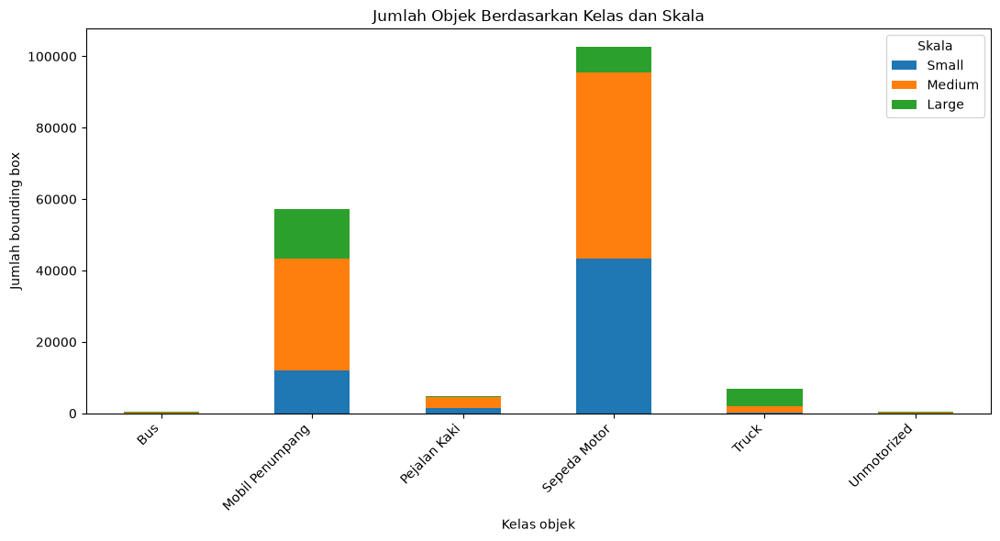

In [ ]:
ax = class_scale_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
)

ax.set_title(
    "Jumlah Objek Berdasarkan Kelas dan Skala"
)

ax.set_xlabel(
    "Kelas objek"
)

ax.set_ylabel(
    "Jumlah bounding box"
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.legend(
    title="Skala"
)

plt.tight_layout()
plt.show()

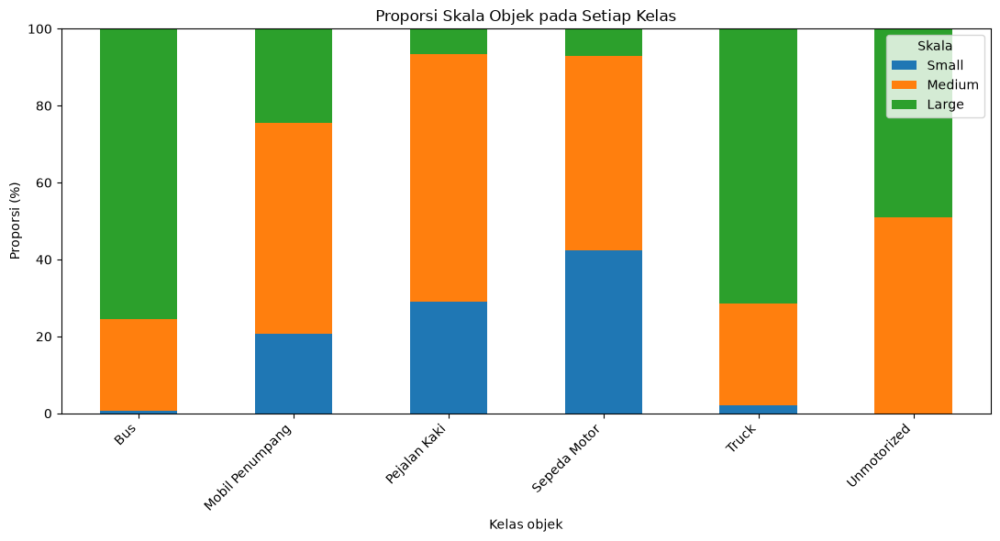

coco_scale,Small,Medium,Large
class_name,,,
Bus,0.77,23.80,75.43
Mobil Penumpang,20.78,54.84,24.38
Pejalan Kaki,29.09,64.21,6.69
Sepeda Motor,42.37,50.59,7.04
Truck,2.08,26.51,71.41
Unmotorized,0.00,51.01,48.99


In [ ]:
class_scale_pct = (
    class_scale_pivot
    .div(
        class_scale_pivot.sum(axis=1),
        axis=0,
    )
    * 100
)

ax = class_scale_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
)

ax.set_title(
    "Proporsi Skala Objek pada Setiap Kelas"
)

ax.set_xlabel(
    "Kelas objek"
)

ax.set_ylabel(
    "Proporsi (%)"
)

ax.set_ylim(
    0,
    100,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.legend(
    title="Skala"
)

plt.tight_layout()
plt.show()


display(
    class_scale_pct.round(2)
)

In [ ]:
# ============================================================
# SCALE DISTRIBUTION BY SPLIT
# ============================================================

split_scale = (
    ann_eda
    .groupby(
        [
            "split",
            "coco_scale",
        ],
        observed=False,
    )
    .size()
    .rename("count")
    .reset_index()
)


split_scale_pivot = (
    split_scale
    .pivot(
        index="split",
        columns="coco_scale",
        values="count",
    )
    .fillna(0)
    .reindex(
        columns=[
            "Small",
            "Medium",
            "Large",
        ],
        fill_value=0,
    )
)


split_scale_pct = (
    split_scale_pivot
    .div(
        split_scale_pivot.sum(axis=1),
        axis=0,
    )
    * 100
)


display(
    split_scale_pct.round(2)
)

coco_scale,Small,Medium,Large
split,,,
test,32.24,52.48,15.28
train,33.51,50.82,15.67
val,31.35,52.74,15.91


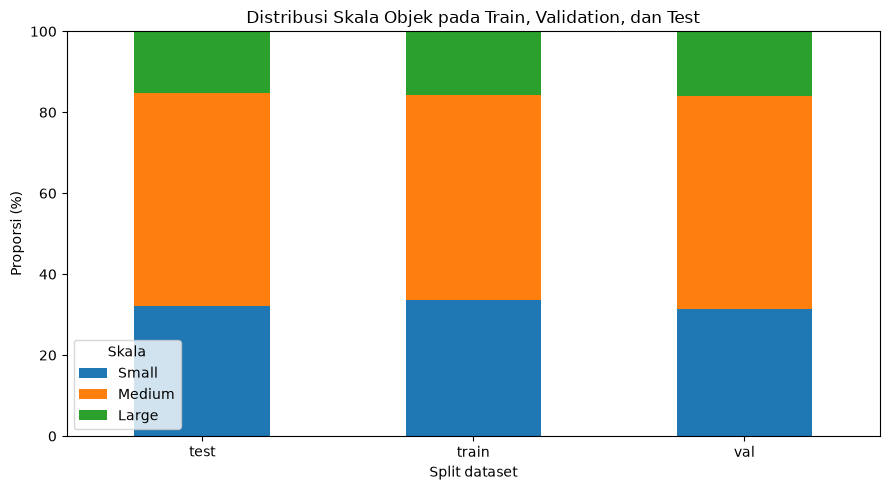

In [ ]:
ax = split_scale_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
)

ax.set_title(
    "Distribusi Skala Objek pada Train, Validation, dan Test"
)

ax.set_xlabel(
    "Split dataset"
)

ax.set_ylabel(
    "Proporsi (%)"
)

ax.set_ylim(
    0,
    100,
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Skala"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# OBJECT DENSITY PER IMAGE
# ============================================================

objects_per_image = (
    ann_eda
    .groupby(
        [
            "split",
            "image_name",
        ]
    )
    .size()
    .rename("object_count")
    .reset_index()
)


objects_per_image = (
    images_df[
        [
            "split",
            "image_name",
        ]
    ]
    .merge(
        objects_per_image,
        on=[
            "split",
            "image_name",
        ],
        how="left",
    )
)

objects_per_image[
    "object_count"
] = (
    objects_per_image[
        "object_count"
    ]
    .fillna(0)
    .astype(int)
)


display(
    objects_per_image[
        "object_count"
    ].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

count    9478.000000
mean       18.207006
std        16.082605
min         0.000000
25%         4.000000
50%        14.000000
75%        28.000000
90%        43.000000
95%        52.000000
99%        63.000000
max        81.000000
Name: object_count, dtype: float64

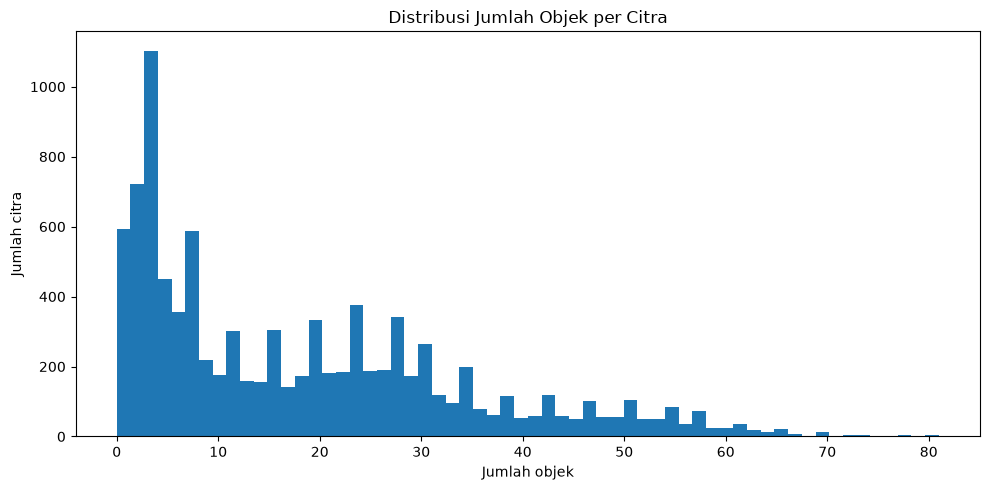

In [ ]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.hist(
    objects_per_image[
        "object_count"
    ],
    bins=60,
)

ax.set_title(
    "Distribusi Jumlah Objek per Citra"
)

ax.set_xlabel(
    "Jumlah objek"
)

ax.set_ylabel(
    "Jumlah citra"
)

plt.tight_layout()
plt.show()

In [ ]:
most_crowded = (
    objects_per_image
    .sort_values(
        "object_count",
        ascending=False,
    )
    .head(20)
)

display(
    most_crowded
)

,split,image_name,object_count
1388,train,Screenshot-2025-05-30-at-21_42_52_png.rf.924ee...,81
1366,train,Screenshot-2025-05-30-at-21_39_09_png.rf.90c3c...,81
1381,train,Screenshot-2025-05-30-at-21_42_13_png.rf.b840e...,80
7064,val,Screenshot-2025-05-31-at-15_02_46_png.rf.4e0f9...,80
1836,train,SP__PLAZA_PANGRANGO_PTZ-08_04_2025-13_27_48_fr...,78
1395,train,Screenshot-2025-05-30-at-21_43_48_png.rf.7e335...,78
1966,train,SP__PLAZA_PANGRANGO_PTZ-08_04_2025-17_41_03_fr...,77
7193,val,SP__PLAZA_PANGRANGO_PTZ-08_04_2025-14_57_47_fr...,77
1925,train,SP__PLAZA_PANGRANGO_PTZ-08_04_2025-16_17_34_fr...,76
1464,train,Screenshot-2025-05-31-at-15_03_46_png.rf.d36c6...,76


In [ ]:
# ============================================================
# PERSPECTIVE VS OBJECT SCALE
# ============================================================

from scipy.stats import spearmanr


perspective_df = ann_eda[
    ann_eda["bbox_area_px"] > 0
].copy()


perspective_df[
    "log_bbox_area"
] = np.log10(
    perspective_df[
        "bbox_area_px"
    ]
)


rho, p_value = spearmanr(
    perspective_df["y_center"],
    perspective_df["log_bbox_area"],
)


print(
    f"Spearman rho : {rho:.4f}"
)

print(
    f"p-value      : {p_value:.6g}"
)

Spearman rho : 0.4143
p-value      : 0


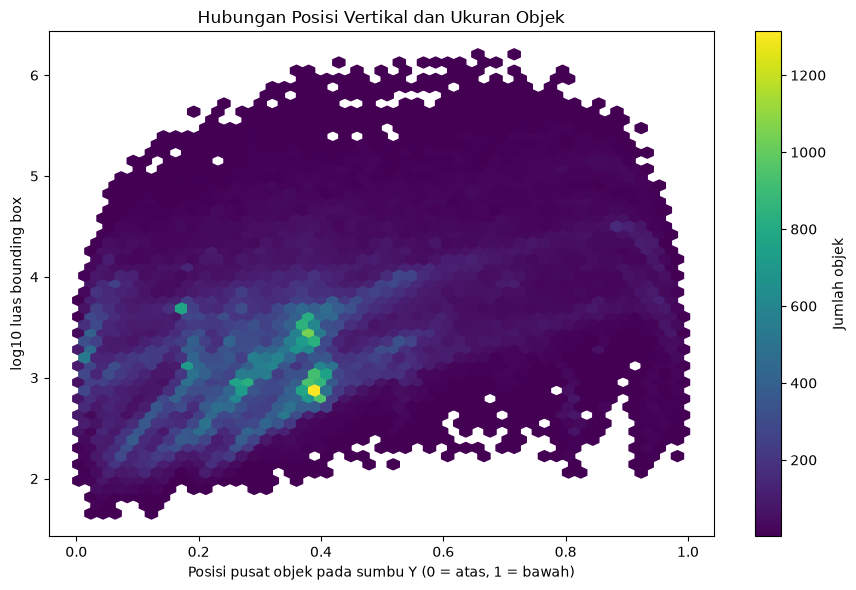

In [ ]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

hb = ax.hexbin(
    perspective_df[
        "y_center"
    ],
    perspective_df[
        "log_bbox_area"
    ],
    gridsize=50,
    mincnt=1,
)

ax.set_title(
    "Hubungan Posisi Vertikal dan Ukuran Objek"
)

ax.set_xlabel(
    "Posisi pusat objek pada sumbu Y "
    "(0 = atas, 1 = bawah)"
)

ax.set_ylabel(
    "log10 luas bounding box"
)

fig.colorbar(
    hb,
    ax=ax,
    label="Jumlah objek",
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# IMAGE ILLUMINATION ANALYSIS
# ============================================================

from PIL import Image
from tqdm.auto import tqdm


illumination_rows = []


for row in tqdm(
    images_df.itertuples(
        index=False
    ),
    total=len(images_df),
    desc="Analyzing illumination",
):

    image_path = Path(
        row.image_path
    )

    try:

        with Image.open(
            image_path
        ) as img:

            img = img.convert("L")

            # cukup kecil untuk statistik luminance
            img.thumbnail(
                (160, 160)
            )

            arr = np.asarray(
                img,
                dtype=np.float32,
            )


        illumination_rows.append(
            {
                "split": row.split,
                "image_name": row.image_name,
                "image_path": row.image_path,
                "mean_luminance": float(
                    arr.mean()
                ),
                "median_luminance": float(
                    np.median(arr)
                ),
                "luminance_std": float(
                    arr.std()
                ),
            }
        )


    except Exception as exc:

        print(
            "[ERROR]",
            image_path,
            exc,
        )


illumination_df = pd.DataFrame(
    illumination_rows
)


display(
    illumination_df[
        [
            "mean_luminance",
            "median_luminance",
            "luminance_std",
        ]
    ].describe()
)

Analyzing illumination:   0%|          | 0/9478 [00:00<?, ?it/s]

,mean_luminance,median_luminance,luminance_std
count,9478.000000,9478.000000,9478.000000
mean,104.965995,102.925881,40.621613
std,16.251051,24.818448,9.704462
min,46.525833,33.000000,13.926571
25%,89.741474,80.000000,31.978150
50%,111.785137,111.000000,42.526287
75%,117.243994,119.000000,48.067190
max,158.942154,154.000000,67.815231


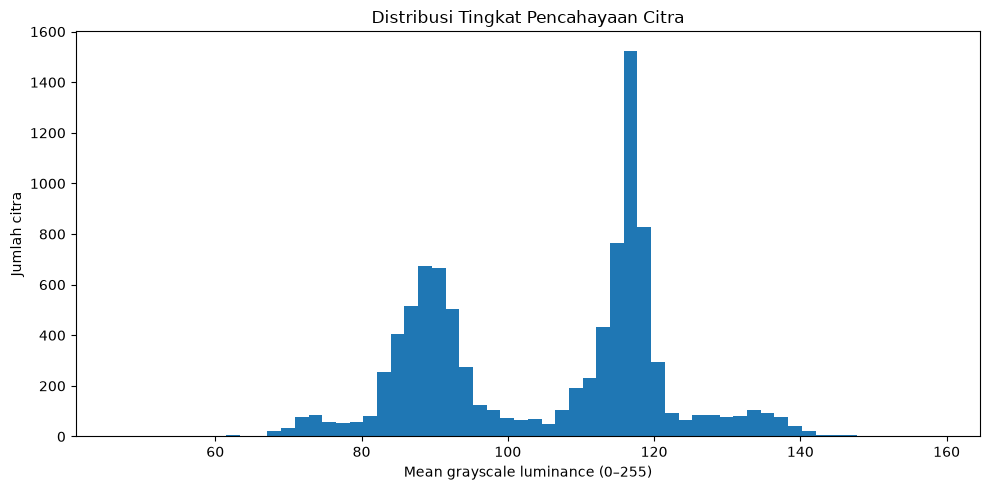

In [ ]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.hist(
    illumination_df[
        "mean_luminance"
    ],
    bins=60,
)

ax.set_title(
    "Distribusi Tingkat Pencahayaan Citra"
)

ax.set_xlabel(
    "Mean grayscale luminance (0–255)"
)

ax.set_ylabel(
    "Jumlah citra"
)

plt.tight_layout()
plt.show()

In [ ]:
darkest = (
    illumination_df
    .nsmallest(
        6,
        "mean_luminance",
    )
)

brightest = (
    illumination_df
    .nlargest(
        6,
        "mean_luminance",
    )
)


display(
    darkest[
        [
            "split",
            "image_name",
            "mean_luminance",
        ]
    ]
)

display(
    brightest[
        [
            "split",
            "image_name",
            "mean_luminance",
        ]
    ]
)

,split,image_name,mean_luminance
1452,train,Screenshot-2025-05-31-at-08_52_37_png.rf.f0593...,46.525833
8706,test,Screenshot-2025-05-31-at-08_52_07_png.rf.4148a...,53.114792
1453,train,Screenshot-2025-05-31-at-08_52_44_png.rf.6c6b3...,56.732571
1457,train,Screenshot-2025-05-31-at-08_53_56_png.rf.873a2...,57.528610
1459,train,Screenshot-2025-05-31-at-08_54_26_png.rf.6594e...,57.639446
7061,val,Screenshot-2025-05-31-at-08_51_20_png.rf.ae1c1...,57.894238


,split,image_name,mean_luminance
616,train,IPCamera_02-10_04_2025-08_07_30_frame_00003_jp...,158.942154
634,train,IPCamera_02-10_04_2025-08_28_37_frame_00007_jp...,152.083893
632,train,IPCamera_02-10_04_2025-08_28_37_frame_00005_jp...,148.930557
621,train,IPCamera_02-10_04_2025-08_07_30_frame_00008_jp...,147.379715
588,train,IPCamera_02-10_04_2025-07_20_47_frame_00009_jp...,147.291382
656,train,IPCamera_02-10_04_2025-09_05_48_frame_00000_jp...,146.700134


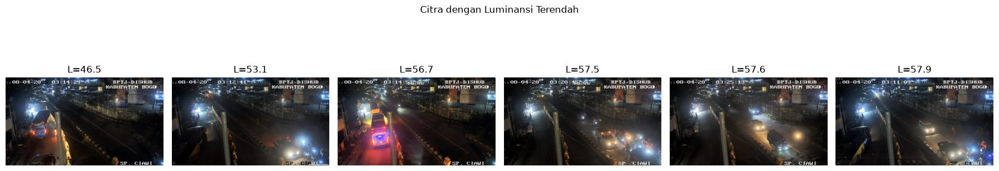

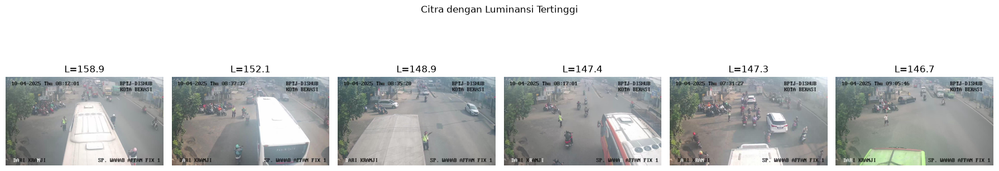

In [ ]:
def show_image_examples(
    dataframe,
    title,
):

    n = len(
        dataframe
    )

    fig, axes = plt.subplots(
        1,
        n,
        figsize=(
            3 * n,
            4,
        ),
    )

    if n == 1:
        axes = [axes]


    for ax, row in zip(
        axes,
        dataframe.itertuples(
            index=False
        ),
    ):

        image = Image.open(
            row.image_path
        ).convert("RGB")

        ax.imshow(
            image
        )

        ax.set_title(
            f"L={row.mean_luminance:.1f}"
        )

        ax.axis(
            "off"
        )


    fig.suptitle(
        title
    )

    plt.tight_layout()
    plt.show()


show_image_examples(
    darkest,
    "Citra dengan Luminansi Terendah",
)

show_image_examples(
    brightest,
    "Citra dengan Luminansi Tertinggi",
)

In [ ]:
# ============================================================
# ILLUMINATION × OBJECT SCALE
# ============================================================

illumination_df[
    "illumination_group"
] = pd.qcut(
    illumination_df[
        "mean_luminance"
    ],
    q=3,
    labels=[
        "Low",
        "Medium",
        "High",
    ],
)


illum_scale_df = (
    ann_eda.merge(
        illumination_df[
            [
                "split",
                "image_name",
                "mean_luminance",
                "illumination_group",
            ]
        ],
        on=[
            "split",
            "image_name",
        ],
        how="left",
    )
)

In [ ]:
illum_scale = (
    illum_scale_df
    .groupby(
        [
            "illumination_group",
            "coco_scale",
        ],
        observed=False,
    )
    .size()
    .rename(
        "count"
    )
    .reset_index()
)


illum_scale_pivot = (
    illum_scale
    .pivot(
        index="illumination_group",
        columns="coco_scale",
        values="count",
    )
    .fillna(0)
    .reindex(
        columns=[
            "Small",
            "Medium",
            "Large",
        ],
        fill_value=0,
    )
)


illum_scale_pct = (
    illum_scale_pivot
    .div(
        illum_scale_pivot.sum(
            axis=1
        ),
        axis=0,
    )
    * 100
)


display(
    illum_scale_pct.round(2)
)

coco_scale,Small,Medium,Large
illumination_group,,,
Low,27.85,59.38,12.78
Medium,27.15,52.67,20.19
High,39.28,48.20,12.51


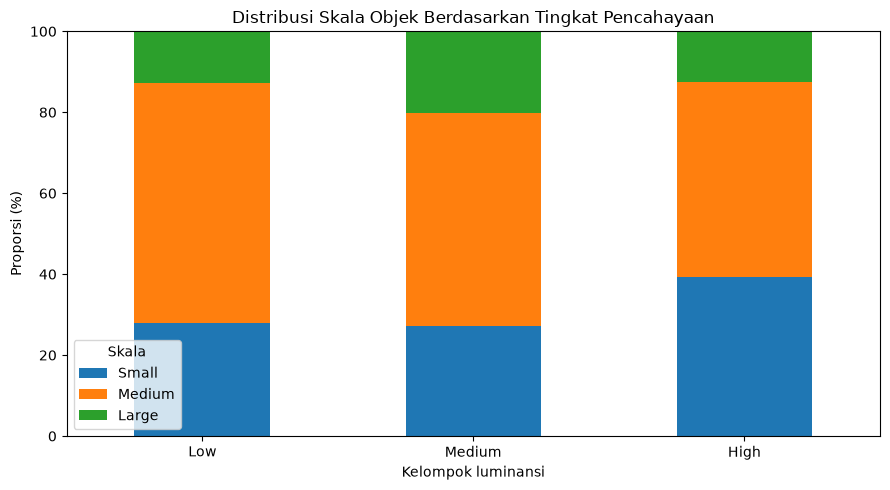

In [ ]:
ax = illum_scale_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
)

ax.set_title(
    "Distribusi Skala Objek Berdasarkan Tingkat Pencahayaan"
)

ax.set_xlabel(
    "Kelompok luminansi"
)

ax.set_ylabel(
    "Proporsi (%)"
)

ax.set_ylim(
    0,
    100,
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Skala"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# GT BOUNDING BOX OVERLAP
# ============================================================

def max_pairwise_iou(
    group
):

    boxes = (
        group[
            [
                "x_center",
                "y_center",
                "width_norm",
                "height_norm",
            ]
        ]
        .to_numpy(
            dtype=float
        )
    )


    n = len(
        boxes
    )


    if n <= 1:
        return np.zeros(
            n
        )


    x = boxes[:, 0]
    y = boxes[:, 1]
    w = boxes[:, 2]
    h = boxes[:, 3]


    x1 = x - w / 2
    y1 = y - h / 2

    x2 = x + w / 2
    y2 = y + h / 2


    inter_x1 = np.maximum(
        x1[:, None],
        x1[None, :],
    )

    inter_y1 = np.maximum(
        y1[:, None],
        y1[None, :],
    )

    inter_x2 = np.minimum(
        x2[:, None],
        x2[None, :],
    )

    inter_y2 = np.minimum(
        y2[:, None],
        y2[None, :],
    )


    inter_w = np.maximum(
        0,
        inter_x2 - inter_x1,
    )

    inter_h = np.maximum(
        0,
        inter_y2 - inter_y1,
    )


    intersection = (
        inter_w
        * inter_h
    )


    area = (
        w
        * h
    )


    union = (
        area[:, None]
        + area[None, :]
        - intersection
    )


    iou = np.divide(
        intersection,
        union,
        out=np.zeros_like(
            intersection
        ),
        where=union > 0,
    )


    np.fill_diagonal(
        iou,
        0,
    )


    return iou.max(
        axis=1
    )

In [ ]:
overlap_parts = []


for (
    split,
    image_name,
), group in tqdm(
    ann_eda.groupby(
        [
            "split",
            "image_name",
        ]
    ),
    desc="Computing GT overlap",
):

    group = group.copy()

    group[
        "max_gt_iou"
    ] = max_pairwise_iou(
        group
    )


    overlap_parts.append(
        group[
            [
                "split",
                "image_name",
                "class_name",
                "max_gt_iou",
            ]
        ]
    )


overlap_df = pd.concat(
    overlap_parts,
    ignore_index=True,
)

Computing GT overlap:   0%|          | 0/9451 [00:00<?, ?it/s]

In [ ]:
overlap_summary = pd.DataFrame(
    {
        "condition": [
            "IoU > 0.10",
            "IoU > 0.30",
            "IoU > 0.50",
        ],
        "percentage": [
            (
                overlap_df[
                    "max_gt_iou"
                ] > 0.10
            ).mean() * 100,

            (
                overlap_df[
                    "max_gt_iou"
                ] > 0.30
            ).mean() * 100,

            (
                overlap_df[
                    "max_gt_iou"
                ] > 0.50
            ).mean() * 100,
        ],
    }
)


display(
    overlap_summary
)

,condition,percentage
0,IoU > 0.10,1.306746
1,IoU > 0.30,0.028974
2,IoU > 0.50,0.005795


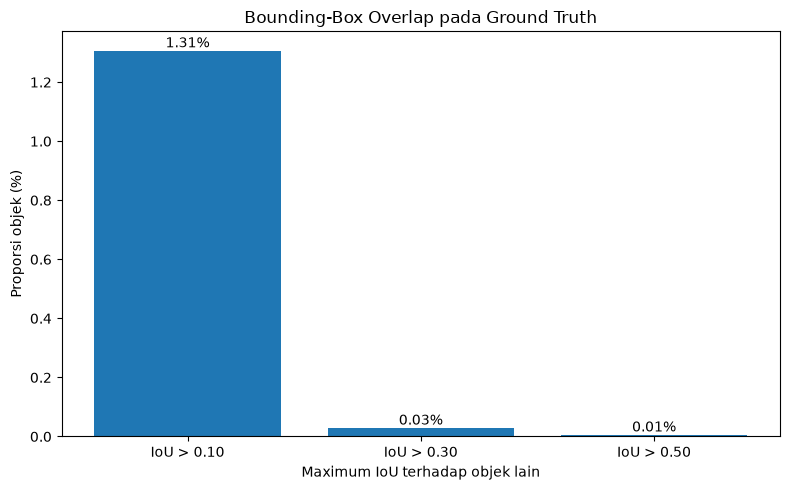

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    overlap_summary[
        "condition"
    ],
    overlap_summary[
        "percentage"
    ],
)


ax.set_title(
    "Bounding-Box Overlap pada Ground Truth"
)

ax.set_xlabel(
    "Maximum IoU terhadap objek lain"
)

ax.set_ylabel(
    "Proporsi objek (%)"
)


for bar, value in zip(
    bars,
    overlap_summary[
        "percentage"
    ],
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
    )


plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# DUPLICATE IMAGE LEAKAGE CHECK
# ============================================================

import hashlib
from pathlib import Path
from tqdm.auto import tqdm


def file_md5(path: Path, chunk_size=1024 * 1024):
    hasher = hashlib.md5()

    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            hasher.update(chunk)

    return hasher.hexdigest()


hash_rows = []

for row in tqdm(
    images_df.itertuples(index=False),
    total=len(images_df),
    desc="Hashing images",
):
    image_path = Path(row.image_path)

    hash_rows.append({
        "split": row.split,
        "image_name": row.image_name,
        "image_path": row.image_path,
        "md5": file_md5(image_path),
    })


hash_df = pd.DataFrame(hash_rows)


duplicate_hashes = (
    hash_df
    .groupby("md5")
    .filter(lambda x: x["split"].nunique() > 1)
    .sort_values("md5")
)


print(
    "Duplicate images across splits:",
    duplicate_hashes["md5"].nunique()
)

display(
    duplicate_hashes.head(30)
)

Hashing images:   0%|          | 0/9478 [00:00<?, ?it/s]

Duplicate images across splits: 0


,split,image_name,image_path,md5


In [ ]:
# ============================================================
# DUPLICATE IMAGE LEAKAGE CHECK
# ============================================================

import hashlib
from pathlib import Path
from tqdm.auto import tqdm


def file_md5(path: Path, chunk_size=1024 * 1024):
    hasher = hashlib.md5()

    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            hasher.update(chunk)

    return hasher.hexdigest()


hash_rows = []

for row in tqdm(
    images_df.itertuples(index=False),
    total=len(images_df),
    desc="Hashing images",
):
    image_path = Path(row.image_path)

    hash_rows.append({
        "split": row.split,
        "image_name": row.image_name,
        "image_path": row.image_path,
        "md5": file_md5(image_path),
    })


hash_df = pd.DataFrame(hash_rows)


duplicate_hashes = (
    hash_df
    .groupby("md5")
    .filter(lambda x: x["split"].nunique() > 1)
    .sort_values("md5")
)


print(
    "Duplicate images across splits:",
    duplicate_hashes["md5"].nunique()
)

display(
    duplicate_hashes.head(30)
)

Hashing images:   0%|          | 0/9478 [00:00<?, ?it/s]

Duplicate images across splits: 0


,split,image_name,image_path,md5


In [ ]:
# ============================================================
# INTERSECTION OVER SMALLER AREA (IoA)
# ============================================================

def max_pairwise_ioa(group):

    boxes = group[
        [
            "x_center",
            "y_center",
            "width_norm",
            "height_norm",
        ]
    ].to_numpy(dtype=float)

    n = len(boxes)

    if n <= 1:
        return np.zeros(n)

    x = boxes[:, 0]
    y = boxes[:, 1]
    w = boxes[:, 2]
    h = boxes[:, 3]

    x1 = x - w / 2
    y1 = y - h / 2
    x2 = x + w / 2
    y2 = y + h / 2

    inter_x1 = np.maximum(
        x1[:, None],
        x1[None, :]
    )

    inter_y1 = np.maximum(
        y1[:, None],
        y1[None, :]
    )

    inter_x2 = np.minimum(
        x2[:, None],
        x2[None, :]
    )

    inter_y2 = np.minimum(
        y2[:, None],
        y2[None, :]
    )

    inter_w = np.maximum(
        0,
        inter_x2 - inter_x1
    )

    inter_h = np.maximum(
        0,
        inter_y2 - inter_y1
    )

    intersection = (
        inter_w * inter_h
    )

    area = w * h

    smaller_area = np.minimum(
        area[:, None],
        area[None, :]
    )

    ioa = np.divide(
        intersection,
        smaller_area,
        out=np.zeros_like(intersection),
        where=smaller_area > 0,
    )

    np.fill_diagonal(
        ioa,
        0
    )

    return ioa.max(axis=1)

Computing IoA:   0%|          | 0/9451 [00:00<?, ?it/s]

,condition,percentage
0,IoA > 0.10,27.522803
1,IoA > 0.30,11.399117
2,IoA > 0.50,6.234137


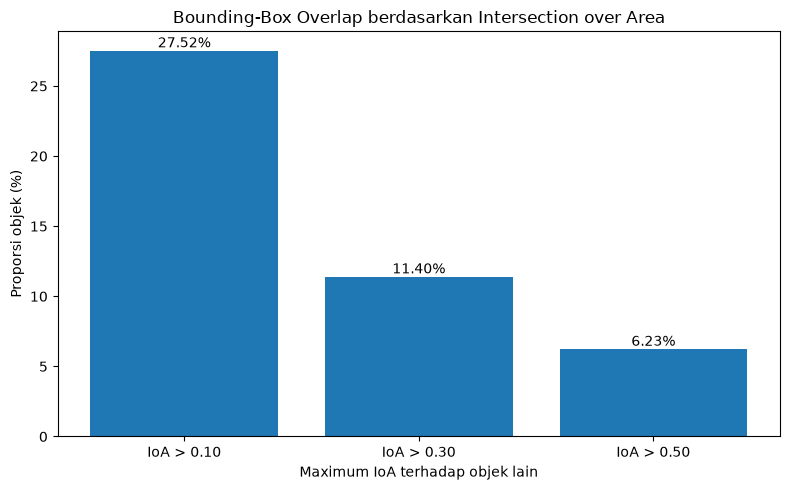

In [ ]:
# ============================================================
# IoA OVERLAP ANALYSIS — SELF CONTAINED
# Tidak menyimpan file apa pun.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm


def max_pairwise_ioa(group):

    boxes = group[
        [
            "x_center",
            "y_center",
            "width_norm",
            "height_norm",
        ]
    ].to_numpy(dtype=float)

    n = len(boxes)

    if n <= 1:
        return np.zeros(n)

    x = boxes[:, 0]
    y = boxes[:, 1]
    w = boxes[:, 2]
    h = boxes[:, 3]

    x1 = x - (w / 2)
    y1 = y - (h / 2)

    x2 = x + (w / 2)
    y2 = y + (h / 2)

    inter_x1 = np.maximum(
        x1[:, None],
        x1[None, :]
    )

    inter_y1 = np.maximum(
        y1[:, None],
        y1[None, :]
    )

    inter_x2 = np.minimum(
        x2[:, None],
        x2[None, :]
    )

    inter_y2 = np.minimum(
        y2[:, None],
        y2[None, :]
    )

    inter_w = np.maximum(
        0,
        inter_x2 - inter_x1
    )

    inter_h = np.maximum(
        0,
        inter_y2 - inter_y1
    )

    intersection = (
        inter_w * inter_h
    )

    area = (
        w * h
    )

    smaller_area = np.minimum(
        area[:, None],
        area[None, :]
    )

    ioa = np.divide(
        intersection,
        smaller_area,
        out=np.zeros_like(intersection),
        where=smaller_area > 0,
    )

    np.fill_diagonal(
        ioa,
        0
    )

    return ioa.max(axis=1)


# ============================================================
# Hitung IoA untuk setiap bounding box
# ============================================================

ioa_parts = []

for (
    split,
    image_name,
), group in tqdm(
    ann_eda.groupby(
        [
            "split",
            "image_name",
        ]
    ),
    desc="Computing IoA",
):

    group = group.copy()

    group["max_gt_ioa"] = (
        max_pairwise_ioa(group)
    )

    ioa_parts.append(
        group[
            [
                "split",
                "image_name",
                "class_name",
                "max_gt_ioa",
            ]
        ]
    )


ioa_df = pd.concat(
    ioa_parts,
    ignore_index=True
)


# ============================================================
# Summary
# ============================================================

thresholds = [
    0.10,
    0.30,
    0.50,
]

ioa_summary = pd.DataFrame({
    "condition": [
        f"IoA > {threshold:.2f}"
        for threshold in thresholds
    ],

    "percentage": [
        (
            ioa_df["max_gt_ioa"]
            > threshold
        ).mean() * 100

        for threshold in thresholds
    ],
})


display(ioa_summary)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    ioa_summary["condition"],
    ioa_summary["percentage"],
)

ax.set_title(
    "Bounding-Box Overlap berdasarkan Intersection over Area"
)

ax.set_xlabel(
    "Maximum IoA terhadap objek lain"
)

ax.set_ylabel(
    "Proporsi objek (%)"
)


for bar, value in zip(
    bars,
    ioa_summary["percentage"],
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        f"{value:.2f}%",

        ha="center",
        va="bottom",
    )


plt.tight_layout()
plt.show()

In [71]:
# ============================================================
# 16. EDA SUMMARY — Ringkasan Hasil Analisis Dataset
# ============================================================

import pprint

eda_summary = {
    "dataset_id":        DATASET_ID,
    "dataset_stage":     DATASET_STAGE,
    # --- Split image counts ---
    "n_images_train":    int((images_df["split"] == "train").sum()),
    "n_images_val":      int((images_df["split"] == "val").sum()),
    "n_images_test":     int((images_df["split"] == "test").sum()),
    "n_images_total":    len(images_df),
    # --- Annotations ---
    "n_annotations":     len(annotations_df),
    "n_classes":         len(class_names),
    "class_names":       class_names,
    # --- Label quality ---
    "n_issues_total":    len(issues_df),
    "n_empty_labels":    int(images_df["label_empty"].sum()),
    # --- BBox stats ---
    "bbox_area_norm_mean":   float(annotations_df["area_norm"].mean()),
    "bbox_area_norm_median": float(annotations_df["area_norm"].median()),
    # --- COCO scale ---
    "coco_scale_pct": {
        row["scale"]: round(row["percentage"], 2)
        for _, row in scale_summary.iterrows()
    },
    # --- Object density ---
    "objects_per_image_mean":   float(objects_per_image["object_count"].mean()),
    "objects_per_image_median": float(objects_per_image["object_count"].median()),
}

# Print ringkasan
pprint.pprint(eda_summary)

# Simpan ke file JSON di EDA_DIR
summary_path = EDA_DIR / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(eda_summary, f, ensure_ascii=False, indent=2)

print(f"\nEDA summary tersimpan di: {summary_path}")


{'bbox_area_norm_mean': 0.004981768443039635,
 'bbox_area_norm_median': 0.0014226466049382714,
 'class_names': ['Bus',
                 'Mobil Penumpang',
                 'Pejalan Kaki',
                 'Sepeda Motor',
                 'Truck',
                 'Unmotorized'],
 'coco_scale_pct': {'Large': 15.68, 'Medium': 51.33, 'Small': 33.0},
 'dataset_id': 'poltrada-original-raw-2-v1',
 'dataset_stage': 'validation-audited',
 'n_annotations': 172566,
 'n_classes': 6,
 'n_empty_labels': 27,
 'n_images_test': 913,
 'n_images_total': 9478,
 'n_images_train': 6775,
 'n_images_val': 1790,
 'n_issues_total': 87,
 'objects_per_image_mean': 18.207005697404515,
 'objects_per_image_median': 14.0}

EDA summary tersimpan di: C:\Local D\Galeri Belajar\Skripsi\outputs\eda\poltrada-original-raw-2-v1\eda_summary.json
